<a href="https://colab.research.google.com/github/anujithpp/DeepLearning/blob/main/DeepLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Q1.Consider a dataset and train a Linear regression model using Batch Gradient descent,SGD,Mini batch(batch size=64)Gd and measure the execution time,no of parameter update ,final loss and based on your observation,identify the most suitable optimizer for large scale dataset

In [1]:
import numpy as np
import time
from sklearn.datasets import load_diabetes

# ----------------------------
# Load Diabetes Dataset
# ----------------------------
diabetes = load_diabetes()

X = diabetes.data      # Input features
y = diabetes.target    # Output

# Add bias column
X = np.c_[np.ones(X.shape[0]), X]

print("Dataset : Diabetes")
print("Samples :", X.shape[0])
print("Features:", X.shape[1] - 1)
print()

# ----------------------------
# Loss Function
# ----------------------------
def loss(X, y, theta):
    prediction = X @ theta
    return np.mean((prediction - y) ** 2)

# ----------------------------
# Batch Gradient Descent
# ----------------------------
def batch_gd(X, y):
    rows, cols = X.shape

    theta = np.zeros(cols)

    learning_rate = 0.1
    epochs = 1000
    updates = 0

    start = time.time()

    for i in range(epochs):

        prediction = X @ theta

        gradient = (X.T @ (prediction - y)) / rows

        theta = theta - learning_rate * gradient

        updates += 1

    end = time.time()

    return end - start, updates, loss(X, y, theta)

# ----------------------------
# Stochastic Gradient Descent
# ----------------------------
def sgd(X, y):
    rows, cols = X.shape

    theta = np.zeros(cols)

    learning_rate = 0.01
    epochs = 1000
    updates = 0

    start = time.time()

    for e in range(epochs):

        for i in range(rows):

            prediction = X[i] @ theta

            gradient = (prediction - y[i]) * X[i]

            theta = theta - learning_rate * gradient

            updates += 1

    end = time.time()

    return end - start, updates, loss(X, y, theta)

# ----------------------------
# Mini Batch Gradient Descent
# ----------------------------
def mini_batch_gd(X, y):
    rows, cols = X.shape

    theta = np.zeros(cols)

    learning_rate = 0.05
    epochs = 1000
    batch_size = 64
    updates = 0

    start = time.time()

    for e in range(epochs):

        for i in range(0, rows, batch_size):

            X_batch = X[i:i + batch_size]
            y_batch = y[i:i + batch_size]

            prediction = X_batch @ theta

            gradient = (X_batch.T @ (prediction - y_batch)) / len(X_batch)

            theta = theta - learning_rate * gradient

            updates += 1

    end = time.time()

    return end - start, updates, loss(X, y, theta)

# ----------------------------
# Train the Models
# ----------------------------
batch = batch_gd(X, y)
stochastic = sgd(X, y)
mini = mini_batch_gd(X, y)

# ----------------------------
# Display Results
# ----------------------------
print("-----------------------------------------------------------")
print("Optimizer\tTime(s)\tUpdates\t\tFinal Loss")
print("-----------------------------------------------------------")

print(f"Batch GD\t{batch[0]:.4f}\t{batch[1]}\t\t{batch[2]:.2f}")

print(f"SGD\t\t{stochastic[0]:.4f}\t{stochastic[1]}\t\t{stochastic[2]:.2f}")

print(f"Mini Batch\t{mini[0]:.4f}\t{mini[1]}\t\t{mini[2]:.2f}")

Dataset : Diabetes
Samples : 442
Features: 10

-----------------------------------------------------------
Optimizer	Time(s)	Updates		Final Loss
-----------------------------------------------------------
Batch GD	0.0313	1000		3937.18
SGD		7.0662	442000		2879.48
Mini Batch	0.1120	7000		3125.69


Q2.Load and preprocess the MNIST dataset.
Design a Neural Network with:
Input Layer = 784 neurons (28×28 image)
Hidden Layer = 128 neurons (ReLU)
Output Layer = 10 neurons (Softmax)
Train the same model using four optimizers:
SGD with Momentum
Adagrad
RMSprop
Adam
Keep all hyperparameters the same except the optimizer.
Compare
Training Accuracy
Validation Accuracy
Training Loss
Validation Loss
Plot Accuracy and Loss for all optimizers.
Identify which optimizer converges faster.Q2.Implement

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset : MNIST
Samples : 60000
Features: 784


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9101 - loss: 0.3088 - val_accuracy: 0.9471 - val_loss: 0.1843
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9567 - loss: 0.1477 - val_accuracy: 0.9630 - val_loss: 0.1240
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9686 - loss: 0.1073 - val_accuracy: 0.9691 - val_loss: 0.1027
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9753 - loss: 0.0841 - val_accuracy: 0.9733 - val_loss: 0.0881
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9800 - loss: 0.0694 - val_accuracy: 0.9743 - val_loss: 0.0822
Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8783 - loss: 0.4535 - val_accuracy: 0.9227 - val_loss: 0.2788
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9262 - loss: 0.2642 - val_accuracy: 0.9349 - val_loss: 0.2310
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9376 - loss: 0.2238 - val_acc

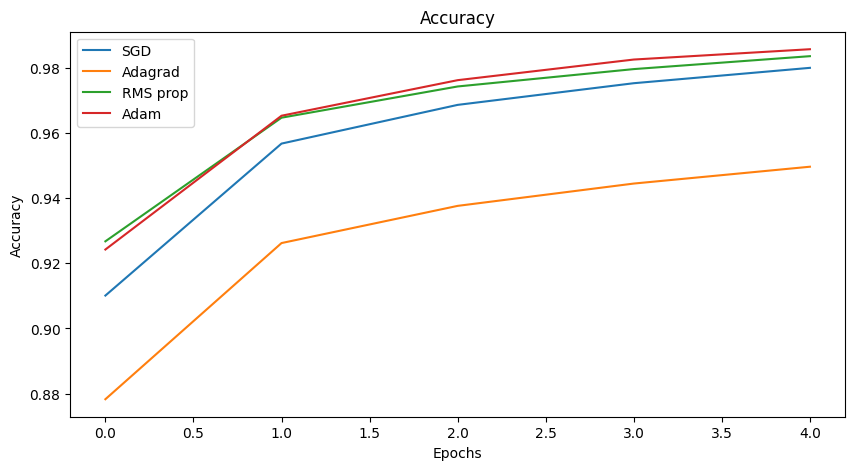

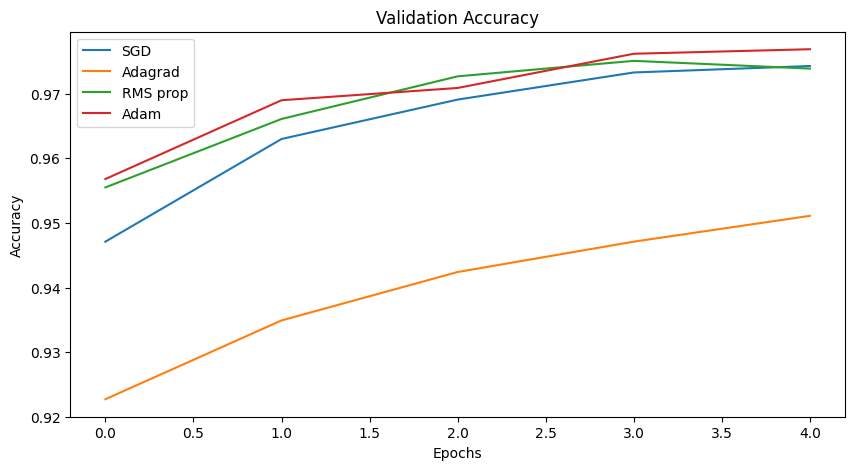

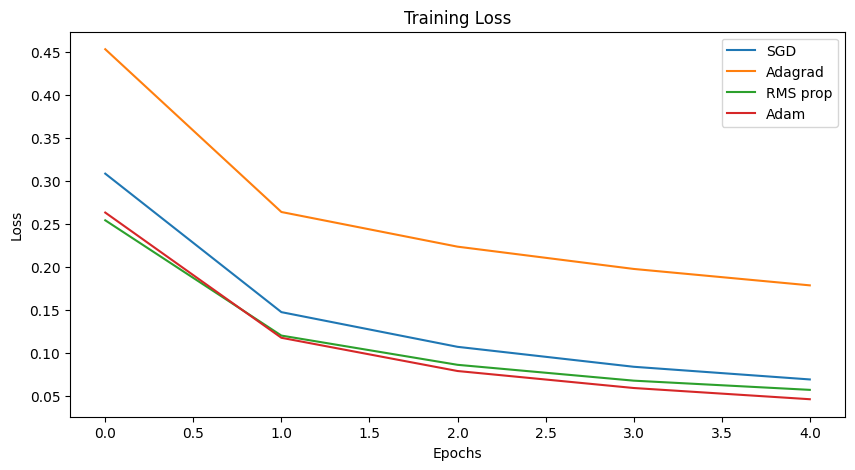

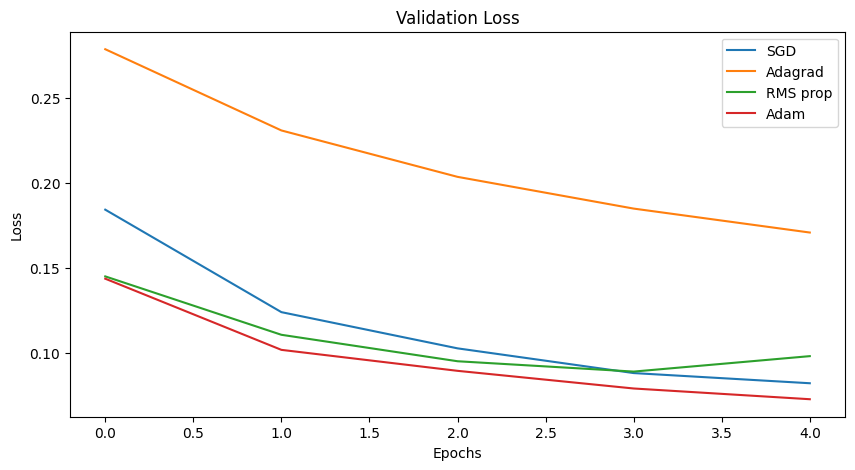

Final Results:

SGD
Training Accuracy: 0.9799833297729492
Validation Accuracy: 0.9743000268936157
Training Loss: 0.06940019875764847
Validation Loss: 0.08215736597776413

Adagrad
Training Accuracy: 0.9496333599090576
Validation Accuracy: 0.9510999917984009
Training Loss: 0.17883481085300446
Validation Loss: 0.17086954414844513

RMS prop
Training Accuracy: 0.9835666418075562
Validation Accuracy: 0.9739000201225281
Training Loss: 0.057278186082839966
Validation Loss: 0.09810950607061386

Adam
Training Accuracy: 0.9857000112533569
Validation Accuracy: 0.9768999814987183
Training Loss: 0.04638959839940071
Validation Loss: 0.07275105267763138


In [2]:
from IPython.core import history
import tensorflow as tf
import matplotlib.pyplot as plt

#Loading dataset
(x_train,y_train),(x_test,y_test)=tf.keras.datasets.mnist.load_data()
#Normalize
x_train=x_train/255.0
x_test=x_test/255.0
#Flatten images
x_train=x_train.reshape(-1,28*28)
x_test=x_test.reshape(-1,28*28)

print("Dataset : MNIST")
print("Samples :", x_train.shape[0])
print("Features:", x_train.shape[1])

#Function to create model
def create_model():
  model=tf.keras.Sequential([
      tf.keras.layers.Dense(128,activation='relu',input_shape=(784,)),
      tf.keras.layers.Dense(10,activation='softmax')
  ])
  return model

epochs=5
batch_size=32

#SGD with Momentum
model_sgd=create_model()
optimizer=tf.keras.optimizers.SGD(learning_rate=0.01,momentum=0.9)
model_sgd.compile(optimizer=optimizer,loss='sparse_categorical_crossentropy',metrics=['accuracy'])
history_sgd=model_sgd.fit(x_train,y_train,epochs=epochs,batch_size=batch_size,validation_data=(x_test,y_test))

#Adagrad
model_adagrad=create_model()
optimizer=tf.keras.optimizers.Adagrad(learning_rate=0.01)
model_adagrad.compile(optimizer=optimizer,loss='sparse_categorical_crossentropy',metrics=['accuracy'])
history_adagrad=model_adagrad.fit(x_train,y_train,epochs=epochs,batch_size=batch_size,validation_data=(x_test,y_test))

#RMS prop
model_rms=create_model()
optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.001)
model_rms.compile(optimizer=optimizer,loss='sparse_categorical_crossentropy',metrics=['accuracy'])
history_rms=model_rms.fit(x_train,y_train,epochs=epochs,batch_size=batch_size,validation_data=(x_test,y_test))

#Adam
model_adam=create_model()
optimizer=tf.keras.optimizers.Adam(learning_rate=0.001)
model_adam.compile(optimizer=optimizer,loss='sparse_categorical_crossentropy',metrics=['accuracy'])
history_adam=model_adam.fit(x_train,y_train,epochs=epochs,batch_size=batch_size,validation_data=(x_test,y_test))

#Plot Accuracy
plt.figure(figsize=(10,5))
plt.plot(history_sgd.history['accuracy'],label='SGD')
plt.plot(history_adagrad.history['accuracy'],label='Adagrad')
plt.plot(history_rms.history['accuracy'],label='RMS prop')
plt.plot(history_adam.history['accuracy'],label='Adam')

plt.title('Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

#Validation accuracy
plt.figure(figsize=(10,5))
plt.plot(history_sgd.history['val_accuracy'],label='SGD')
plt.plot(history_adagrad.history['val_accuracy'],label='Adagrad')
plt.plot(history_rms.history['val_accuracy'],label='RMS prop')
plt.plot(history_adam.history['val_accuracy'],label='Adam')

plt.title('Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

#Training Loss
plt.figure(figsize=(10,5))
plt.plot(history_sgd.history['loss'],label='SGD')
plt.plot(history_adagrad.history['loss'],label='Adagrad')
plt.plot(history_rms.history['loss'],label='RMS prop')
plt.plot(history_adam.history['loss'],label='Adam')

plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

#Validation Loss
plt.figure(figsize=(10,5))
plt.plot(history_sgd.history['val_loss'],label='SGD')
plt.plot(history_adagrad.history['val_loss'],label='Adagrad')
plt.plot(history_rms.history['val_loss'],label='RMS prop')
plt.plot(history_adam.history['val_loss'],label='Adam')

plt.title('Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()
#Comparing final results
print("Final Results:")
print("\nSGD")
print("Training Accuracy:",history_sgd.history['accuracy'][-1])
print("Validation Accuracy:",history_sgd.history['val_accuracy'][-1])
print("Training Loss:",history_sgd.history['loss'][-1])
print("Validation Loss:",history_sgd.history['val_loss'][-1])

print("\nAdagrad")
print("Training Accuracy:",history_adagrad.history['accuracy'][-1])
print("Validation Accuracy:",history_adagrad.history['val_accuracy'][-1])
print("Training Loss:",history_adagrad.history['loss'][-1])
print("Validation Loss:",history_adagrad.history['val_loss'][-1])

print("\nRMS prop")
print("Training Accuracy:",history_rms.history['accuracy'][-1])
print("Validation Accuracy:",history_rms.history['val_accuracy'][-1])
print("Training Loss:",history_rms.history['loss'][-1])
print("Validation Loss:",history_rms.history['val_loss'][-1])

print("\nAdam")
print("Training Accuracy:",history_adam.history['accuracy'][-1])
print("Validation Accuracy:",history_adam.history['val_accuracy'][-1])
print("Training Loss:",history_adam.history['loss'][-1])
print("Validation Loss:",history_adam.history['val_loss'][-1])



**Conclusion**

The MNIST dataset was effectively classified using a neural network with a single hidden layer of 128 neurons. Training was conducted with four different optimizers: SGD with Momentum, Adagrad, RMSprop, and Adam.

Adam delivered the strongest results, achieving:

Training Accuracy: 98.62%

Validation Accuracy: 97.66%

Training Loss: 0.0456

Validation Loss: 0.0706

RMSprop performed comparably to Adam and converged rapidly.

SGD with Momentum demonstrated consistent learning but converged more slowly than Adam and RMSprop.

Adagrad produced the weakest results, with lower accuracy and higher loss, primarily due to its diminishing learning rate.

Overall, Adam proved to be the most effective optimizer for this task, offering the highest accuracy, lowest loss, and fastest convergence among the tested methods.

**Q3**. Implement a Generative Adversarial Network (GAN) using TensorFlow/Keras to generate handwritten digit images from the MNIST dataset.

include

Loading and preprocessing the MNIST dataset

Designing the Generator network.

Designing the Discriminator network

Training the GAN for a specified number of epochs.

Generating and displaying at least 16 synthetic handwritten digit images.

Expected Output

Trained GAN model.
Generated handwritten digits.
Loss values of Generator and Discriminator.
Plot the Generator loss.
Plot the Discriminator loss.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

# ---------------------------------------------------------------
# 1. HYPERPARAMETERS
# ---------------------------------------------------------------
LATENT_DIM  = 100          # Size of the random noise vector
EPOCHS      = 50           # Number of training epochs
BATCH_SIZE  = 128
IMAGE_SHAPE = (28, 28, 1)

# ---------------------------------------------------------------
# 2. LOAD & PREPROCESS THE MNIST DATASET
# ---------------------------------------------------------------
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values to [-1, 1] to match the generator's tanh output
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = x_train.reshape(-1, 28, 28, 1)      # Add channel dimension

# Build an efficient tf.data pipeline
dataset = (tf.data.Dataset.from_tensor_slices(x_train)
           .shuffle(60000)
           .batch(BATCH_SIZE, drop_remainder=True)
           .prefetch(tf.data.AUTOTUNE))

print(f"Training samples: {len(x_train)}")

# ---------------------------------------------------------------
# 3. GENERATOR NETWORK
#    Maps random noise (100-D) -> 28x28x1 image
# ---------------------------------------------------------------
def build_generator(latent_dim=LATENT_DIM):
    model = models.Sequential(name="Generator")

    # Project and reshape the noise vector
    model.add(layers.Dense(7 * 7 * 256, use_bias=False, input_shape=(latent_dim,)))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())
    model.add(layers.Reshape((7, 7, 256)))

    # Upsample: 7x7 -> 7x7
    model.add(layers.Conv2DTranspose(128, (5, 5), strides=(1, 1),
                                     padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    # Upsample: 7x7 -> 14x14
    model.add(layers.Conv2DTranspose(64, (5, 5), strides=(2, 2),
                                     padding="same", use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU())

    # Upsample: 14x14 -> 28x28, single channel, tanh output in [-1, 1]
    model.add(layers.Conv2DTranspose(1, (5, 5), strides=(2, 2),
                                     padding="same", use_bias=False,
                                     activation="tanh"))
    return model

# ---------------------------------------------------------------
# 4. DISCRIMINATOR NETWORK
#    Classifies 28x28x1 image as real (1) or fake (0)
# ---------------------------------------------------------------
def build_discriminator():
    model = models.Sequential(name="Discriminator")

    model.add(layers.Conv2D(64, (5, 5), strides=(2, 2), padding="same",
                            input_shape=IMAGE_SHAPE))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Conv2D(128, (5, 5), strides=(2, 2), padding="same"))
    model.add(layers.LeakyReLU())
    model.add(layers.Dropout(0.3))

    model.add(layers.Flatten())
    model.add(layers.Dense(1))   # raw logit (no sigmoid; handled in loss)
    return model

generator     = build_generator()
discriminator = build_discriminator()

generator.summary()
discriminator.summary()

# ---------------------------------------------------------------
# 5. LOSSES & OPTIMIZERS
# ---------------------------------------------------------------
bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_logits, fake_logits):
    real_loss = bce(tf.ones_like(real_logits),  real_logits)   # real images -> 1
    fake_loss = bce(tf.zeros_like(fake_logits), fake_logits)   # fake images -> 0
    return real_loss + fake_loss

def generator_loss(fake_logits):
    return bce(tf.ones_like(fake_logits), fake_logits)         # fool discriminator

generator_optimizer     = tf.keras.optimizers.Adam(1e-4, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.5)

# ---------------------------------------------------------------
# 6. TRAINING STEP
# ---------------------------------------------------------------
@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, LATENT_DIM])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_logits = discriminator(images, training=True)
        fake_logits = discriminator(generated_images, training=True)

        g_loss = generator_loss(fake_logits)
        d_loss = discriminator_loss(real_logits, fake_logits)

    grads_g = gen_tape.gradient(g_loss, generator.trainable_variables)
    grads_d = disc_tape.gradient(d_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(grads_g, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(grads_d, discriminator.trainable_variables))

    return g_loss, d_loss

# ---------------------------------------------------------------
# 7. TRAINING LOOP
# ---------------------------------------------------------------
fixed_noise = tf.random.normal([16, LATENT_DIM])   # Reused to track progress
g_losses, d_losses = [], []

for epoch in range(1, EPOCHS + 1):
    epoch_g, epoch_d = [], []
    for batch in dataset:
        g_loss, d_loss = train_step(batch)
        epoch_g.append(g_loss)
        epoch_d.append(d_loss)

    g_losses.append(float(np.mean(epoch_g)))
    d_losses.append(float(np.mean(epoch_d)))
    print(f"Epoch {epoch:>3}/{EPOCHS} | "
          f"G Loss: {g_losses[-1]:.4f} | D Loss: {d_losses[-1]:.4f}")

# ---------------------------------------------------------------
# 8. GENERATE & DISPLAY 16 SYNTHETIC DIGITS
# ---------------------------------------------------------------
generated = generator(fixed_noise, training=False)
generated = (generated + 1) / 2.0        # Rescale [-1, 1] -> [0, 1]

plt.figure(figsize=(6, 6))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(generated[i, :, :, 0], cmap="gray")
    plt.axis("off")
plt.title("Generated Handwritten Digits")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------
# 9. PLOT GENERATOR & DISCRIMINATOR LOSSES
# ---------------------------------------------------------------
plt.figure(figsize=(9, 5))
plt.plot(range(1, EPOCHS + 1), g_losses, label="Generator Loss",     marker="o", markersize=3)
plt.plot(range(1, EPOCHS + 1), d_losses, label="Discriminator Loss", marker="o", markersize=3)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Losses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# ---------------------------------------------------------------
# 10. SAVE THE TRAINED MODEL (optional)
# ---------------------------------------------------------------
generator.save("gan_generator_mnist.h5")
print("✅ Training complete. Generator saved as 'gan_generator_mnist.h5'.")

Training samples: 60000


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,600 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,944 (8.89 MB)

...

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)